### IPD440 - APRENDIZAJE DE MAQUINAS
# Clase 19: Model-Free RL
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Introducción

<div align="right">
    <img src="img/Q_Learning_Header.png" alt="" width="40%" align="right" />
</div>

El aprendizaje por refuerzo (RL) es la parte del ecosistema de aprendizaje automático donde el agente aprende interactuando con el entorno para obtener la estrategia óptima para lograr los objetivos. Es bastante diferente de los algoritmos de aprendizaje automático supervisados, donde necesitamos ingerir y procesar esos datos. El aprendizaje por refuerzo no requiere datos. En cambio, aprende del entorno y del sistema de recompensas para tomar mejores decisiones.

**Ejemplo:** En el videojuego Mario, si un personaje realiza una acción aleatoria (por ejemplo, moverse hacia la izquierda), en función de esa acción, puede recibir una recompensa. Después de realizar la acción, el agente (Mario) se encuentra en un nuevo estado y el proceso se repite hasta que el personaje del juego llega al final de la etapa o muere. Este episodio se repetirá varias veces hasta que Mario aprenda a navegar por el entorno maximizando las recompensas.

<div align="center">
    <img src="img/Mario_RL.png" alt="" width="40%" align="center" />
</div>

# Taxonomía algoritmos de RL

<div align="center">
    <img src="img/rl_algorithms.svg" alt="" width="80%" align="center" />
</div>

# Model-based and model-free learning

En el aprendizaje por refuerzo (RL), existen dos enfoques principales para que un agente tome decisiones:

* **Model-Based RL (aprendizaje basado en modelo):** Aquí, el agente tiene (o construye) un modelo del entorno, que le permite predecir las consecuencias de sus acciones y planificar en consecuencia. Esto significa que el agente puede imaginar diferentes escenarios antes de actuar. Este enfoque es beneficioso cuando es posible hacer predicciones precisas del entorno y se quiere aprovechar esta capacidad para tomar decisiones más informadas y eficientes.

* **Model-Free RL (aprendizaje sin modelo):** El agente no tiene un modelo del entorno; es decir, no intenta predecir cómo sus acciones afectarán el estado futuro. En lugar de eso, el agente aprende qué acciones son buenas o malas basándose solo en sus experiencias directas y en las recompensas obtenidas. Ejemplos de algoritmos de este tipo son **Q-learning** y **Policy Gradient**. Este enfoque es útil cuando el entorno es muy complejo o impredecible.

# ¿Qué es Q-Learning?

- Q-learning (la “Q” significa calidad), es un algoritmo de aprendizaje por refuerzo y se utiliza para que un agente aprenda a tomar decisiones secuenciales en un entorno determinado para maximizar una recompensa acumulativa a lo largo del tiempo.

- Especialmente útil en situaciones en las que un agente debe aprender a tomar decisiones óptimas en un entorno complejo y dinámico.

# ¿Cómo funciona Q-Learning?


## 1. Modelo del agente y el entorno

El agente toma decisiones en el entorno y recibe recompensas como resultado de sus acciones. El objetivo del agente es aprender a tomar decisiones que maximicen la recompensa acumulativa a largo plazo.

## 2. Estado y acciones

El entorno se divide en diferentes estados, que representan situaciones o configuraciones específicas. El agente puede tomar una serie de acciones en cada estado.

## 3. Q-Values 

Se utiliza una función llamada "Q-value" (o función Q) para estimar la recompensa acumulativa esperada de tomar una acción particular en un estado específico. En otras palabras, el Q-value de un par estado-acción indica cuánta recompensa se espera acumular si el agente elige esa acción en ese estado. La función Q utiliza la ecuación de Bellman que recibe el par estado-acción como entrada.

<div align="center">
    <img src="img/Bellman_Equation.png" alt="" width="50%" align="center" />
</div>

## 4. Actualización de Q-Values

El agente comienza con valores Q iniciales arbitrarios y luego, a medida que interactúa con el entorno, actualiza los valores Q en función de las recompensas reales obtenidas. La actualización de los Q-values se realiza utilizando la siguiente fórmula:

<div align="center">
    <img src="img/updateQ-table.png" alt="" width="70%" align="center" />
</div>

* $Q(S, a)$ es el Q-value actual para el estado $S$ y la acción $a$.
* $α$ (alfa) es la tasa de aprendizaje que controla cuánto se actualiza el Q-value en cada paso.
* $R$ es la recompensa real obtenida al tomar la acción a en el estado $S$.
* $γ$ (gamma) es el factor de descuento que refleja la importancia de las recompensas a largo plazo.
* $max(Q(S_{t+1}, a))$ es el valor $Q$ máximo estimado para el próximo estado $S_{t+1}$ y todas las posibles acciones $a$.


El proceso de actualización de los Q-values se repite a lo largo de múltiples episodios de interacción con el entorno hasta que los valores convergen y el agente ha aprendido una política óptima, es decir, una estrategia que maximiza la recompensa a lo largo del tiempo.

## 5. Exploración vs. Explotación

Para aprender de manera efectiva, el agente debe equilibrar la exploración de nuevas acciones con la explotación de acciones que ya ha aprendido que son buenas. Esto se logra mediante una estrategia como epsilon-greedy, donde el agente elige la mejor acción conocida con probabilidad 1-ε y una acción aleatoria con probabilidad ε.

# Ejemplo Frozen Lake

Aprenderemos en detalle cómo funciona Q-learning utilizando el ejemplo de un lago congelado. En este entorno, el agente deberá atravesar el lago helado desde el inicio (I) hasta la meta (G), sin caer en los agujeros (H). La mejor estrategia es alcanzar las metas tomando el camino más corto.

<div align="center">
    <img src="img/Q_Learning_Final.gif" alt="" width="20%" align="center" />
</div>

## Recompensas

* La recompensa por alcanzar la meta es +100
* La recompensa por tomar el camino equivocado (caer al hoyo) es -100
* La recompensa por moverse en el lago congelado es -1.

In [1]:
import random
from collections import defaultdict, namedtuple
from itertools import product, starmap

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import Image, YouTubeVideo
from scipy import stats
%matplotlib inline
sns.set()
states_colors = matplotlib.colors.ListedColormap(
    ['#b3ffff', '#000066', '#e6b800', '#663300'])

cmap_default = 'Reds'
cpal_default = sns.color_palette(("Blues_d"))

sns.set_style("white")
sns.set_context("poster")
random.seed(1)

In [2]:
State = namedtuple('State', ['m', 'n'])

all_states = [State(0, 0), State(0, 1), State(0, 2), State(0, 3), 
              State(1, 0), State(1, 1), State(1, 2), State(1, 3), 
              State(2, 0), State(2, 1), State(2, 2), State(2, 3),
              State(3, 0), State(3, 1), State(3, 2), State(3, 3)]

In [3]:
holes = [ State(m=1, n=1),
                 State(m=1, n=3),
                 State(m=2, n=3),
                 State(m=3, n=0)]

start_state = State(m=0, n=0)
goal_state = State(m=3, n=3)

In [4]:
terminal = holes + [goal_state]
dflt_reward = -1
hole_reward = -100

In [5]:
moves = {'>': State(0, 1),
         'v': State(1, 0),
         '<': State(0, -1),
         '^': State(-1, 0)}

In [6]:
parameters = {'all_states': all_states,
              'holes': holes,
              'goal_state': goal_state,
              'start_state': start_state,
              'terminal': terminal,
              'dflt_reward': dflt_reward,
              'hole_reward': hole_reward,
              'moves': moves}

In [7]:
rewards = np.full((4,4), -1, dtype='int64')
color = np.zeros((4,4))
for x in all_states:
    if x == start_state:
        rewards[x] = -1
        color[x] = 4
    if x == goal_state:
        rewards[x] = 100
        color[x] = 2
    if x in holes:
        rewards[x] = -100
        color[x] = 1

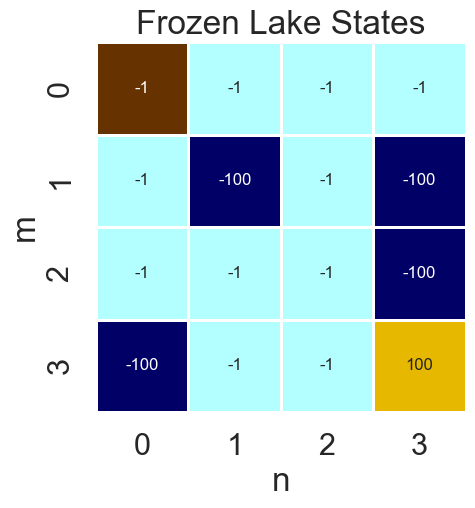

In [8]:
ax = sns.heatmap(color, cmap=states_colors, annot=rewards, cbar=False, 
                 square=True, linewidths=1, fmt='', annot_kws={"size": 12} )
ax.set_title('Frozen Lake States')
ax.set(ylabel='m', xlabel='n')
plt.show()

In [9]:
class FrozenLakeWorld:
    """FrozenLakeWorld domain for RL.

    A simple domain with 4 x 4 = 16 possible discrete states.
   
    Args:

    Specified in the dictionary above because this class is not
    intended for use outside this notebook.


    """

    def __init__(self, *initial_data, **kwargs):
        for dictionary in initial_data:
            for key in dictionary:
                setattr(self, key, dictionary[key])
        for key in kwargs:
            setattr(self, key, kwargs[key])
        self.record_list = []
        self.position = [self.start_state]
        self.log_dict = {}
        self.reward_sum = 0

    def newstate(self, state, action):
        """Computes the newstate.

        Takes a state and an action from the agent and computes its next position.

        Args:
            state: a tuple (m, n)  representing the coordinates of the current state
            action: index of an action

        Returns:
            newstate: a tuple (m, n) representing the coordinates of the new position

        """
        move = moves[action]
        newstate = State(state.m + move.m, state.n + move.n)
        self.position.append(newstate)
        return newstate

    def reward(self, state):
        """Computes the reward signal for a given state.

        Takes a state and checks if it's a hole or just a normal state.

        Args:
            state: a named tuple (m, n) 
                representing the coordinates of the current state.

        Returns:
            reward: a scalar value. -100 for a hole state, -1 otherwise.

        """
        if state in self.holes:
            reward = self.hole_reward
        else:
            reward = self.dflt_reward
        self.reward_sum += reward
        return reward

    def is_terminal(self, state):
        """Checks if state is terminal.

        If the agent reached its goal or fell off a hole the episode ends.
        Otherwise it will continue.

        Args:
            state: namedtuple, State(m, n), representing position.

        Returns:
            True if state is terminal, False otherwise.

        """
        if state in self.terminal:
            self.log_stuff(state)
            return True
        else:
            return False

    def log_stuff(self, state):
        """Log things for analysis.

        You can safely ignore this.
        I will refactor this as a mixin or use a decorator instead later.

        """
        self.position.append(state)
        self.log_dict['visited_states'] = self.position[:]
        self.log_dict['reward'] = self.reward_sum
        self.record_list.append(self.log_dict)
        self.log_dict = {}
        self.position = [self.start_state]
        self.log_dict = {}
        self.reward_sum = 0
        pass

    def valid_actions(self, state):
        """Compute valid actions for given state.

        It's unimportant for understanding RL. Just ignore.

        """

        valid_actions = []
        if (state.m + moves['>'].m, state.n + moves['>'].n) in self.all_states:
            valid_actions.append('>')
        if (state.m + moves['v'].m, state.n + moves['v'].n) in self.all_states:
            valid_actions.append('v')
        if (state.m + moves['<'].m, state.n + moves['<'].n) in self.all_states:
            valid_actions.append('<')
        if (state.m + moves['^'].m, state.n + moves['^'].n) in self.all_states:
            valid_actions.append('^')
        return valid_actions

In [10]:
class RandomAgent:
    """Just choosing actions at random. Learns nothing.

    We write this for the purpose of understanding the interface between
    agent and domain we later use for the real RL-agent.

    """

    def __init__(self):
        self.reward_sum = 0
        pass

    def act(self, state, valid_actions):
        """Take state and valid actions for that state. Return  action."""
        action = random.choice(valid_actions)
        return action

    def learn(self, state, action, newstate, reward):
        """Never learns anything. Basically like the AFD."""
        self.reward_sum += reward
        pass

In [11]:
#: Just some agent randomly roaming through a 
#: gridlike domain with 4x4 discrete states.

random_agent = RandomAgent()    #: Instantiate an agent object
domain = FrozenLakeWorld(parameters) #: Create our small world

def run_episode(domain, agent):
    state = domain.start_state
    while not domain.is_terminal(state):
        valid_actions = domain.valid_actions(state) #: Get a list of allowed moves for the current state.
        action = agent.act(state, valid_actions)    #: Take the current state as input and compute an action.
        newstate = domain.newstate(state, action)   #: Take the action and compute the changed state.
        reward = domain.reward(newstate)            #: Compute reward.
        agent.learn(state, action, newstate, reward)#: Learn.
        state = newstate                            #: Newstate becomes the current state for next iteration.
    pass

run_episode(domain, random_agent)

In [12]:
agent_position_log = domain.record_list[-1]['visited_states']

agent_path = np.empty((4, 4), dtype=str)

for state_visited in agent_position_log:
    if state_visited in terminal:
        agent_path[state_visited] = 'X'
    else:
        agent_path[state_visited] = 'O'

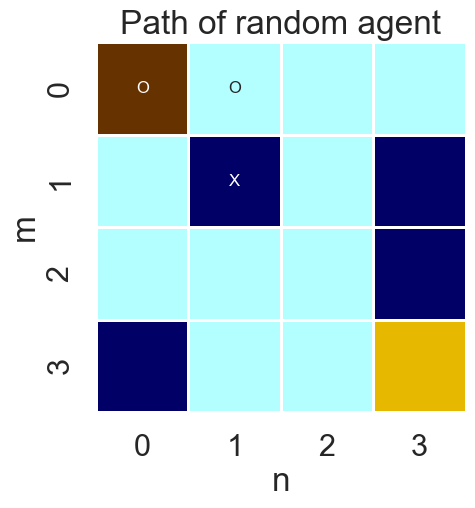

In [13]:
figure = sns.heatmap(color, annot = agent_path, fmt = '', cbar=False, linewidth = 1, 
                     cmap = states_colors, square=True, annot_kws={"size": 12})
figure.set_title('Path of random agent')
figure.set(xlabel='n', ylabel='m')
plt.show()

In [14]:
class QAgent:
    """Q-Learning agent.

    A value based, off-policy RL-agent.
    Uses defaultdict to return 0 for unknown state/action pairs.
    This has the same purpose as initializing all unknown states to zero.


    Args:
        epsilon: Parameter for epsilon-greedy action selection.
        epsilon_modifier: scalar value between 0 and 1,
        decay factor for epsilon
        alpha: Learning rate or stepsize. Usually <<1
        gamma: discount of future rewards <=1

    Attrs:
        Q: Python defaultdict with defaultvalue 0 containing
        the Q-values for state action pairs.
        Keyed by a nested state action tuple.
        Example:
        {
            (State(m=0, n=0), '>'): -99.94360791266038,
            (State(m=0, n=0), 'v'): -1.1111111111107184,
            (State(m=1, n=0), '>'): -1.111111111107987,
            (State(m=1, n=0), 'v'): -1.1111111111079839,
            (State(m=1, n=0), '^'): -1.111111111108079
        }
        A: Defaultdict keyed by state tuple, values
        are keys of executed actions. Is used to determine
        whether an action in a state took place in the past.
        If there's no memory len(A[state]) == 0


    """

    def __init__(self, alpha, epsilon, gamma):
        self.epsilon = epsilon
        self.alpha = alpha
        self.gamma = gamma
        self.Q = defaultdict(int)
        self.A = defaultdict(set)
        self.td_list = []

    def act(self, state, valid_actions):
        """Choose action.

        Take state tuple and valid actions and choose action.
        Action can either be random or greedy to ensure exploration.
        Probability of selecting random actions depends on epsilon.
        Smaller epsilon means less randomness.

        Args:
            state: state tuple (n,m) describes current position.
            valid_actions: list of indices of valid actions for a state.

        Returns:
            action: Index of selected action.
            Can either be chosen at random or greedily.

        """
        if random.random() > self.epsilon:
            action = self.act_greedy(state, valid_actions)
        else:
            action = self.act_random(valid_actions)
        return action

    def learn(self, state, action, newstate, reward):
        """Compute update of Q-function.

        Update Q-values when reaching new state and receiving reward.
        New value equals to the old value + the computed td-error times
        the stepsize parameter alpha.
        Also adds the executed action to A, to keep track of all state
        action pairs.


        Args:
            state: namedtuple (m, n) the state of the last timestep.
            action: index of executed action at the last timestep.
            newstate: current state reached after executing action.
            reward: scalar value received for reaching newstate.


        Returns:
            pass

        """
        self.Q[state, action] = (self.Q[state, action] + self.alpha *
                                 (self.td(state, action, newstate, reward)))
        self.A[state].add(action)
        pass

    def act_random(self, valid_actions):
        """Choose index of action from valid actions at random.

        Called either if epsilon greedy policy returns random
        or if there's no previous knowledge of action values for
        a state.

        Args:
            valid: List of indices of valid actions for a state.

        Returns:
            action: Index of selected action.
                Can either be chosen at random or greedy.

        """
        random_action = random.choice(valid_actions)
        return random_action

    def act_greedy(self, state, valid_actions):
        """Choose action with the highest Q-value.

        First checks whether the agent previously has executed any actions at all
        in the current state. If not it calls the random act_random method.

        Args:
            valid_actions: List of indices of valid actions for a state.
            state: namedtuple, State(n, m),
                representing coordinates of the current state.

        Returns:
            chosen_action: Index of selected action.
                Can either be chosen at random or greedy.

        """
        if len(self.A[state]) == 0:
            chosen_action = self.act_random(valid_actions)
        else:
            q_s = {actions: self.Q[state, actions]
                   for actions in self.A[state]}
            chosen_action = max(q_s, key=q_s.get)
        return chosen_action

    def td(self, state, action, newstate, reward):
        """Compute td error to update value dict

        First checks wether the agent previously as executed any actions at all in
        the current state. If not the maximum Q-value for that state defaults to 0.
        It fetches Q-values for all previously exectued actions in newstate tracked in A.
        Next computes the key of the largest Q-value and queris the fetches Q-values.
        Finally computes the td error for the learning update.

        Args:
            state: state of the last timestep.
            action: index of selected action in that state
            newstate: state the agent just reached.
            reward: scalar value

        Returns:
            td: td error. You know, cocaine, baby.

        """
        if len(self.A[newstate]) == 0:
            max_qval = 0
        else:
            q_vals = {actions: self.Q[newstate, actions]
                      for actions in self.A[newstate]}
            max_qval_key = max(q_vals, key=q_vals.get)
            max_qval = q_vals[max_qval_key]
        td = reward + self.gamma * max_qval - self.Q[state, action]
        self.td_list.append(td)
        return td

In [15]:
def run_experiment(domain, agent, epsilon_decay, n_episodes):
    for i in range(n_episodes):
        agent.epsilon *= epsilon_decay
        run_episode(domain, agent)
    print('Setting epsilon parameter to zero',
          'to prevent random actions and evaluate learned policy.\n')
    agent.epsilon = 0
    run_episode(domain, agent)
    last_reward = domain.record_list[-1]['reward']
    print('Trained for {0} episodes.\n' 
          '\nGained reward of {1} points in the last episode.'.format(n_episodes, last_reward))                       
    pass

In [16]:
epsilon = 0.9
epsilon_decay = 0.99
gamma = 0.9
alpha = 0.25
n_episodes = 500

In [17]:
q_agent = QAgent(alpha, epsilon, gamma)
domain = FrozenLakeWorld(parameters)

In [18]:
run_experiment(domain, q_agent, epsilon_decay, n_episodes)

logged_data = domain.record_list
Q_table = q_agent.Q
A_table = q_agent.A
td = q_agent.td_list

Setting epsilon parameter to zero to prevent random actions and evaluate learned policy.

Trained for 500 episodes.

Gained reward of -6 points in the last episode.


In [19]:
action_array = np.empty((4,4), dtype=str)
value_array = np.empty((4,4), dtype=float)
for state in domain.all_states:
    if len(A_table[state])==0:
        chosen_action = 'H'
    else:
        q_s = {actions: Q_table[state, actions] 
               for actions in A_table[state]}
        chosen_action = max(q_s, key=q_s.get)
        max_qval = q_s[chosen_action]
    action_array[state] = chosen_action
    value_array[state] = max_qval
    action_array[(3,3)] = 'G'

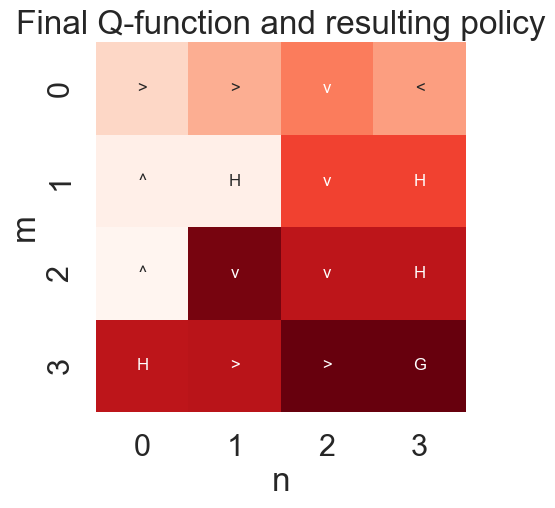

In [20]:
figure = sns.heatmap(value_array, annot = action_array,  fmt = '', square = True, 
                     cbar = False, cmap = cmap_default, annot_kws = {"size": 12})
figure.set_title('Final Q-function and resulting policy')
figure.set(xlabel='n', ylabel='m')
plt.show()

In [21]:
agent_position_log = domain.record_list[-1]['visited_states']

agent_path = np.empty((4, 4), dtype=str)

for state_visited in agent_position_log:
    if state_visited in terminal:
        agent_path[state_visited] = 'X'
    else:
        agent_path[state_visited] = 'O'

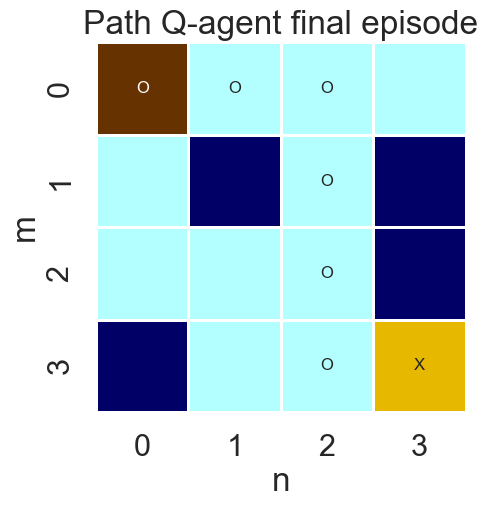

In [22]:
figure = sns.heatmap(color, annot=agent_path, fmt='', cbar=False, linewidth=1,
                     cmap=states_colors, square=True, annot_kws={"size": 12})
figure.set_title('Path Q-agent final episode')
figure.set(xlabel='n', ylabel='m')
plt.show()

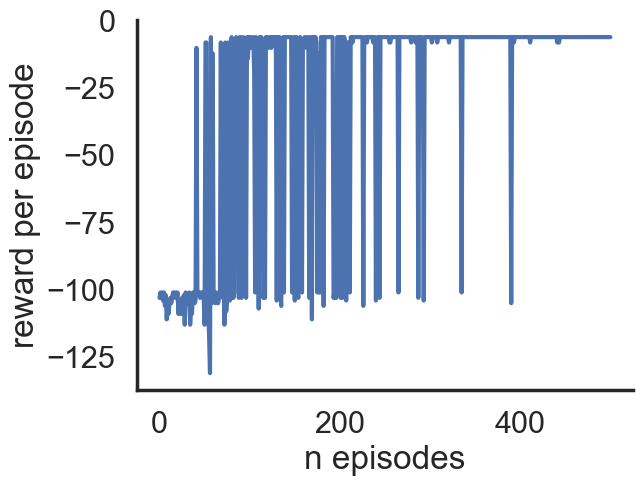

In [23]:
points = [i['reward'] for i in logged_data]
figure = sns.lineplot(points)
figure.set(xlabel='n episodes', ylabel='reward per episode')
sns.despine()

# Policy Optimization

Policy Optimization es un enfoque en el aprendizaje por refuerzo que se enfoca en mejorar directamente la "política" de un agente, es decir, las reglas que sigue para decidir qué acción tomar en cada situación. En lugar de simplemente aprender un valor para cada acción (como en Q-learning), los métodos de policy optimization ajustan la política de manera continua para maximizar las recompensas. Este enfoque ayuda a que el agente aprenda de forma más estable y eficiente en entornos complejos.

# Proximal Policy Optimization (PPO)

PPO (Proximal Policy Optimization) es un algoritmo popular y eficaz para policy optimization en RL. Su objetivo es ajustar la política de manera que no cambie demasiado de un paso a otro, evitando cambios drásticos que puedan desestabilizar el aprendizaje. PPO es conocido por ser eficiente, relativamente fácil de implementar y proporcionar buenos resultados en muchos tipos de problemas de RL.

# Pasos 1 a 3

1. Recoger Experiencias: El agente interactúa con el entorno durante un cierto número de pasos y guarda la experiencia (estados, acciones, recompensas obtenidas, etc.). Esto se llama "batch" de datos de entrenamiento.

2. Estimar las Ventajas (Advantage Estimation): Para cada estado en el batch, PPO calcula cuánto mejor fue la acción tomada en comparación con el promedio de lo esperado (ventaja). Este valor de ventaja ayuda a entender si una acción específica fue mejor o peor de lo normal en ese estado.

3. Calcular la Ratio de Probabilidades: PPO compara la probabilidad de tomar cada acción según la política actual (nueva política) frente a la política anterior. Esto se llama ratio de probabilidad. Si este ratio es muy alto o bajo, significa que la nueva política ha cambiado mucho en comparación con la anterior.

# Pasos 4 a 6

4. Aplicar una Limitación (Clip) al Cambio de Política: PPO usa un "clip" en el ratio de probabilidad para evitar cambios grandes en la política. El objetivo es que la política se ajuste de manera gradual, sin desviarse demasiado de la versión anterior. Esto ayuda a mantener el aprendizaje estable.

5. Actualizar la Política: PPO maximiza la recompensa esperada (basada en las ventajas) mientras respeta el límite de cambio en la política. Esto se hace usando optimización, ajustando la política para que favorezca las acciones con alta ventaja sin cambiar bruscamente.

6. Repetir el Proceso: Una vez que la política ha sido actualizada, el agente vuelve a recolectar nuevas experiencias con la política ajustada y repite los pasos anteriores.

# Training AI to Play Pokemon with Reinforcement Learning

<video width="384" height="216" controls src="img/Training AI to Play Pokemon with Reinforcement Learning.mp4" />